In [1]:

from google.colab import files

uploaded = files.upload()


Saving dataset.zip to dataset.zip


In [2]:

import zipfile
import os

# Lokasi file ZIP
zip_path = "/content/dataset.zip"

# Folder tujuan ekstraksi
extract_path = "/content/dataset_ekstrak"

# Ekstrak dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")
print("Lokasi:", extract_path)

# Melihat isi folder
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            continue


Dataset berhasil diekstrak!
Lokasi: /content/dataset_ekstrak
dataset_ekstrak/
  __MACOSX/
    dataset/
  dataset/
    brown/
    white/
    blue/
    orange/
    red/
    purple/
    grey/
    pink/
    green/
    black/
    yellow/


In [3]:

# Menentukan lokasi dataset utama
dataset_path = "/content/dataset_ekstrak/dataset"

# Memeriksa apakah folder tersedia
import os

if os.path.exists(dataset_path):
    print("Folder dataset ditemukan!")
else:
    print("Folder dataset tidak ditemukan!")


Folder dataset ditemukan!


In [4]:

import os
import pandas as pd

# Format gambar yang akan diperiksa
format_gambar = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Menyimpan hasil inventarisasi
data_kelas = []

# Membaca setiap folder warna
for kelas in sorted(os.listdir(dataset_path)):

    folder_kelas = os.path.join(dataset_path, kelas)

    if os.path.isdir(folder_kelas):

        gambar = [
            file for file in os.listdir(folder_kelas)
            if file.lower().endswith(format_gambar)
        ]

        data_kelas.append({
            'Nama Warna': kelas,
            'Jumlah Gambar': len(gambar)
        })

# Membuat DataFrame
df = pd.DataFrame(data_kelas)

# Menampilkan tabel
print("TABEL DISTRIBUSI DATASET")
display(df)

# Total dataset
print("Total kelas:", len(df))
print("Total gambar:", df['Jumlah Gambar'].sum())


TABEL DISTRIBUSI DATASET


,Nama Warna,Jumlah Gambar
0,black,433
1,blue,645
2,brown,676
3,green,707
4,grey,677
5,orange,438
6,pink,401
7,purple,451
8,red,667
9,white,706


Total kelas: 11
Total gambar: 6199


In [5]:

import os
import shutil

# Hapus folder hasil ekstraksi lama
if os.path.exists("/content/dataset_ekstrak"):
    shutil.rmtree("/content/dataset_ekstrak")

# Hapus ZIP lama
if os.path.exists("/content/dataset.zip"):
    os.remove("/content/dataset.zip")

print("Dataset lama berhasil dibersihkan!")


Dataset lama berhasil dibersihkan!


In [6]:

from google.colab import files

uploaded = files.upload()


Saving dataset.zip to dataset.zip


In [7]:

import zipfile
import os

# Ambil nama ZIP yang baru saja di-upload
zip_path = list(uploaded.keys())[0]
extract_path = "/content/dataset_baru"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP berhasil diekstrak!")
print("Nama file:", zip_path)


ZIP berhasil diekstrak!
Nama file: dataset.zip


In [8]:

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")


dataset_baru/
  dataset/
    brown/
    white/
    blue/
    orange/
    red/
    purple/
    grey/
    pink/
    green/
    black/
    yellow/


In [9]:

import os
import pandas as pd

dataset_path = "/content/dataset_baru/dataset"
format_gambar = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

data_kelas = []

for kelas in sorted(os.listdir(dataset_path)):
    folder_kelas = os.path.join(dataset_path, kelas)

    if os.path.isdir(folder_kelas):
        gambar = [
            file for file in os.listdir(folder_kelas)
            if file.lower().endswith(format_gambar)
        ]

        data_kelas.append({
            'Nama Warna': kelas,
            'Jumlah Gambar': len(gambar)
        })

df = pd.DataFrame(data_kelas)

display(df)

print("Total kelas:", len(df))
print("Total gambar:", df["Jumlah Gambar"].sum())


,Nama Warna,Jumlah Gambar
0,black,433
1,blue,419
2,brown,411
3,green,395
4,grey,399
5,orange,438
6,pink,401
7,purple,418
8,red,418
9,white,418


Total kelas: 11
Total gambar: 4548


In [10]:

import os
from PIL import Image
import pandas as pd
from collections import Counter

dataset_path = "/content/dataset_baru/dataset"

format_gambar = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

hasil_pemeriksaan = []
gambar_rusak = []
format_counter = Counter()

for kelas in sorted(os.listdir(dataset_path)):
    folder_kelas = os.path.join(dataset_path, kelas)

    if not os.path.isdir(folder_kelas):
        continue

    for nama_file in os.listdir(folder_kelas):
        if nama_file.lower().endswith(format_gambar):
            path = os.path.join(folder_kelas, nama_file)
            format_file = os.path.splitext(nama_file)[1].lower()
            format_counter[format_file] += 1

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    lebar, tinggi = img.size

                hasil_pemeriksaan.append({
                    "Kelas": kelas,
                    "Nama File": nama_file,
                    "Format": format_file,
                    "Lebar": lebar,
                    "Tinggi": tinggi,
                    "Status": "Valid"
                })

            except Exception as e:
                gambar_rusak.append({
                    "Kelas": kelas,
                    "Nama File": nama_file,
                    "Lokasi": path,
                    "Error": str(e)
                })

df_kualitas = pd.DataFrame(hasil_pemeriksaan)
df_rusak = pd.DataFrame(gambar_rusak)

print("TOTAL GAMBAR VALID:", len(df_kualitas))
print("TOTAL GAMBAR RUSAK:", len(df_rusak))
print("\nDISTRIBUSI FORMAT:")
display(pd.DataFrame(
    format_counter.items(),
    columns=["Format", "Jumlah"]
))

print("\nCONTOH GAMBAR RUSAK:")
display(df_rusak.head(10))


TOTAL GAMBAR VALID: 4548
TOTAL GAMBAR RUSAK: 0

DISTRIBUSI FORMAT:


,Format,Jumlah
0,.jpg,4357
1,.png,188
2,.jpeg,3



CONTOH GAMBAR RUSAK:


""


In [11]:

# Statistik dimensi gambar

print("JUMLAH DIMENSI GAMBAR:")
display(
    df_kualitas.groupby(["Lebar", "Tinggi"])
    .size()
    .reset_index(name="Jumlah")
    .sort_values("Jumlah", ascending=False)
    .head(20)
)

print("\nSTATISTIK LEBAR:")
display(df_kualitas["Lebar"].describe())

print("\nSTATISTIK TINGGI:")
display(df_kualitas["Tinggi"].describe())

print("\nJUMLAH DIMENSI UNIK:")
print(
    df_kualitas.groupby(["Lebar", "Tinggi"]).ngroups
)


JUMLAH DIMENSI GAMBAR:


,Lebar,Tinggi,Jumlah
42,224,224,4218
115,360,360,98
116,480,480,95
104,240,320,8
78,240,240,4
65,240,180,3
58,240,140,2
71,240,212,2
68,240,189,2
111,240,353,2



STATISTIK LEBAR:


,Lebar
count,4548.000000
mean,232.012973
std,41.947117
min,65.000000
25%,224.000000
50%,224.000000
75%,224.000000
max,480.000000



STATISTIK TINGGI:


,Tinggi
count,4548.000000
mean,234.126209
std,45.005587
min,40.000000
25%,224.000000
50%,224.000000
75%,224.000000
max,480.000000



JUMLAH DIMENSI UNIK:
117


Beberapa temuan:
- 4.218 gambar berukuran 224 × 224.
- 98 gambar berukuran 360 × 360.
- 95 gambar berukuran 480 × 480.
- Sisanya memiliki ukuran yang beragam.
- Dimensi terkecil adalah 65 × 40 piksel.
- Dimensi terbesar adalah 480 × 480 piksel.
Kesimpulan: dataset didominasi gambar persegi berukuran 224 × 224, tetapi masih terdapat variasi resolusi dan rasio aspek.

Sekarang kita lihat apakah gambar dalam setiap kelas memang merepresentasikan warna yang sesuai, sekaligus mengamati objek, latar belakang, dan pencahayaannya.

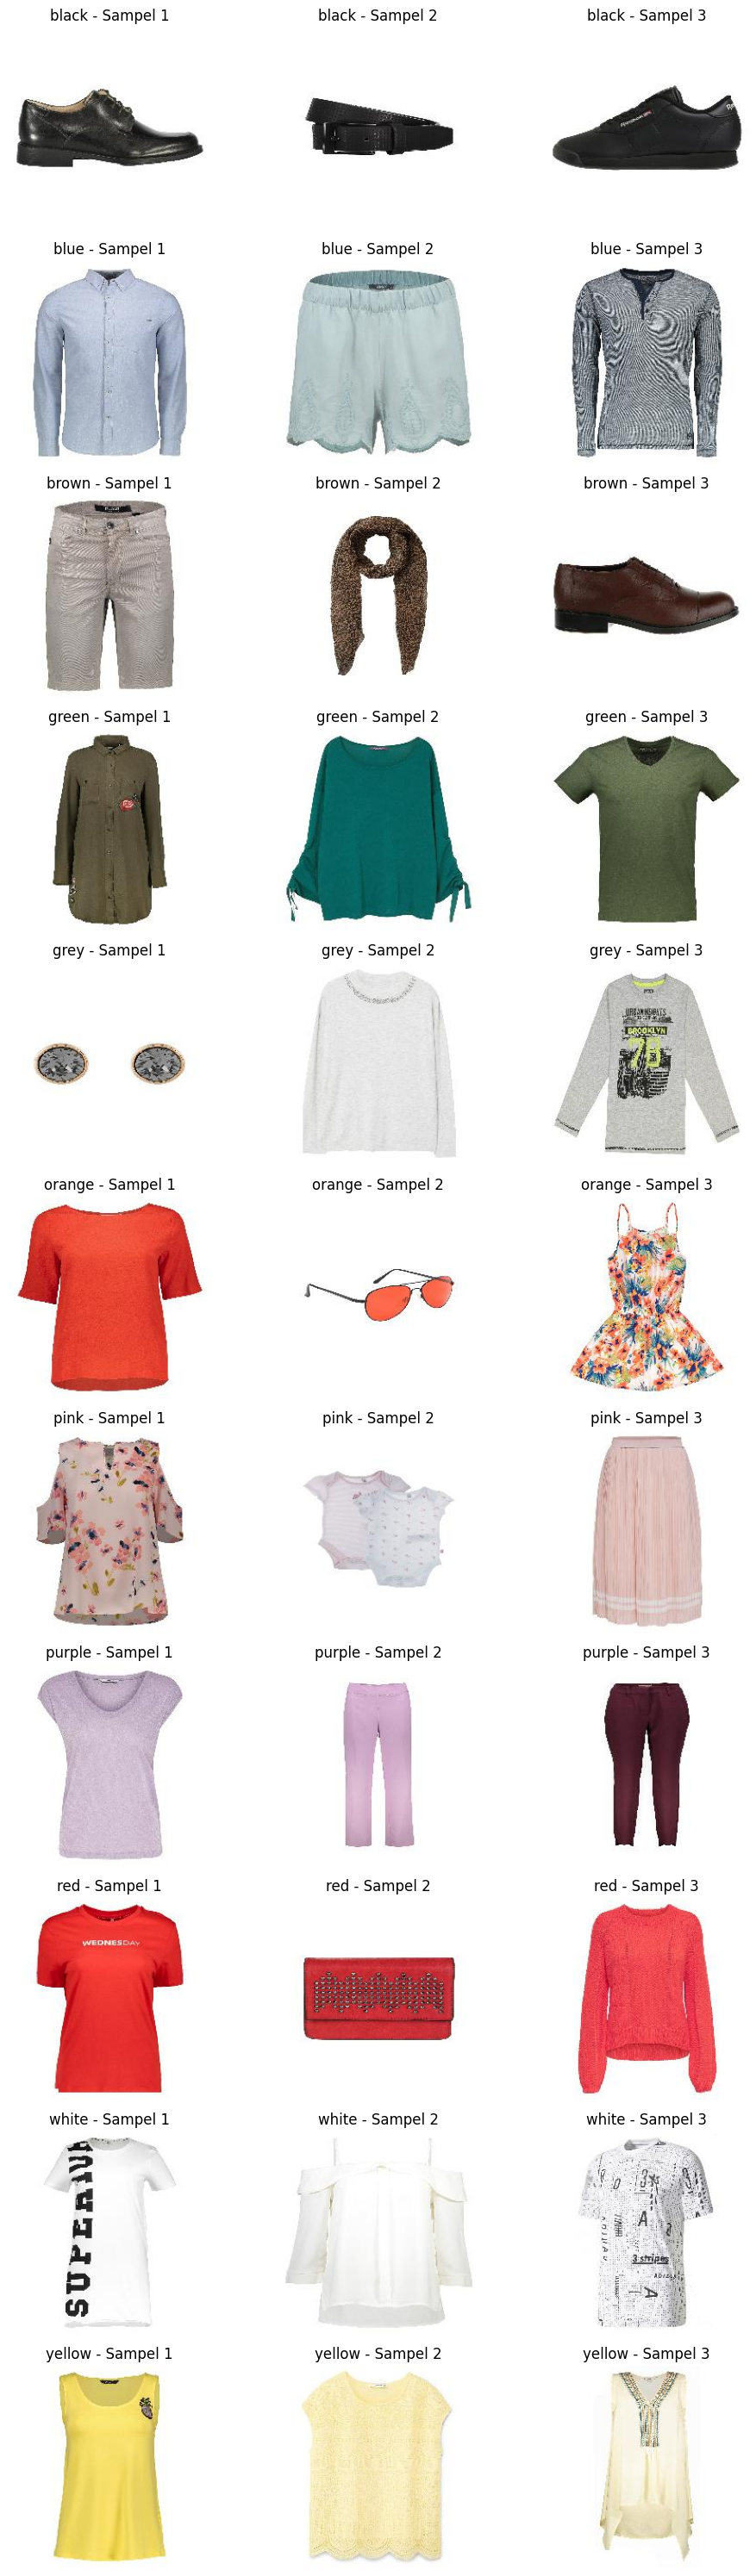

In [12]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

kelas_warna = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

fig, axes = plt.subplots(
    nrows=len(kelas_warna),
    ncols=3,
    figsize=(10, 30)
)

for i, kelas in enumerate(kelas_warna):
    folder = os.path.join(dataset_path, kelas)

    gambar = [
        f for f in os.listdir(folder)
        if f.lower().endswith(format_gambar)
    ]

    sampel = random.sample(gambar, min(3, len(gambar)))

    for j in range(3):
        ax = axes[i, j]

        if j < len(sampel):
            path = os.path.join(folder, sampel[j])

            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(f"{kelas} - Sampel {j+1}")

        ax.axis("off")

plt.tight_layout()
plt.show()


Kita catat hasil EDA sementara:
Pemeriksaan	Hasil
Jumlah kelas	11 kelas
Total gambar	4.548
Gambar rusak	0
Format gambar	JPG, PNG, JPEG
Dimensi dominan	224 × 224
Dimensi unik	117
Kesesuaian label sampel	Sesuai

**Selanjutnya: pemeriksaan gambar duplikat**

In [13]:

import os
import hashlib
from collections import defaultdict

hash_gambar = defaultdict(list)

for kelas in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, kelas)

    if not os.path.isdir(folder):
        continue

    for nama_file in os.listdir(folder):
        if nama_file.lower().endswith(format_gambar):
            path = os.path.join(folder, nama_file)

            with open(path, "rb") as f:
                isi = f.read()
                hash_file = hashlib.md5(isi).hexdigest()

            hash_gambar[hash_file].append({
                "kelas": kelas,
                "nama_file": nama_file,
                "path": path
            })

duplikat = {
    h: file_list
    for h, file_list in hash_gambar.items()
    if len(file_list) > 1
}

print("Jumlah kelompok gambar duplikat:", len(duplikat))
print("Jumlah file yang terlibat duplikasi:",
      sum(len(v) for v in duplikat.values()))

for daftar in list(duplikat.values())[:10]:
    print("\nDuplikat:")
    for item in daftar:
        print(item["kelas"], "-", item["nama_file"])


Jumlah kelompok gambar duplikat: 3
Jumlah file yang terlibat duplikasi: 6

Duplikat:
black - 105299824.jpg
black - 105239887.jpg

Duplikat:
blue - 105257820.jpg
blue - 105257820 - Copy.jpg

Duplikat:
brown - 117091306.jpg
yellow - 117091306.jpg


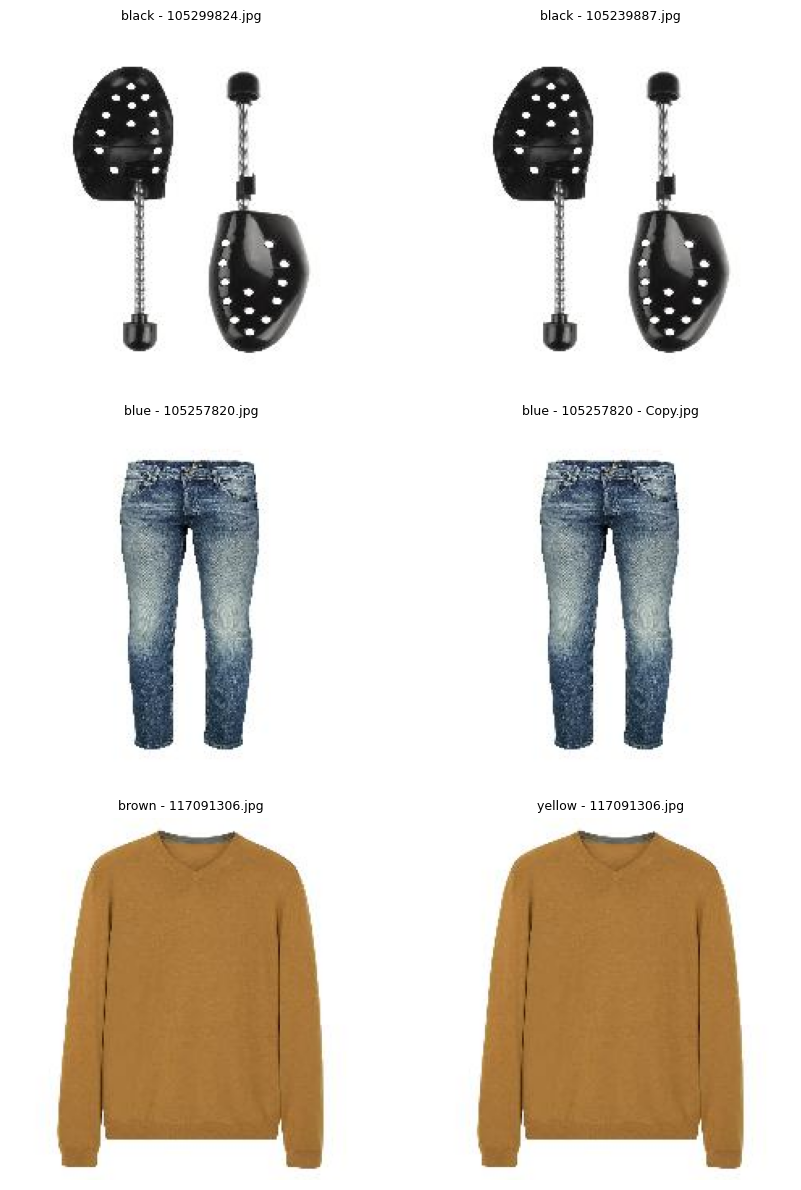

In [14]:

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 2, figsize=(9, 12))

for i, (hash_value, daftar) in enumerate(duplikat.items()):
    for j, item in enumerate(daftar):
        with Image.open(item["path"]) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(
            f'{item["kelas"]} - {item["nama_file"]}',
            fontsize=9
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


hapus duplikat

In [15]:

import os

file_dihapus = [
    os.path.join(dataset_path, "black", "105239887.jpg"),
    os.path.join(dataset_path, "blue", "105257820 - Copy.jpg")
]

for path in file_dihapus:
    if os.path.exists(path):
        os.remove(path)
        print("Berhasil dihapus:", path)
    else:
        print("File tidak ditemukan:", path)


Berhasil dihapus: /content/dataset_baru/dataset/black/105239887.jpg
Berhasil dihapus: /content/dataset_baru/dataset/blue/105257820 - Copy.jpg


In [16]:

import os

file_yellow = os.path.join(
    dataset_path, "yellow", "117091306.jpg"
)

if os.path.exists(file_yellow):
    os.remove(file_yellow)
    print("Duplikat berhasil dihapus dari kelas Yellow!")
else:
    print("File tidak ditemukan.")


Duplikat berhasil dihapus dari kelas Yellow!


In [17]:

for kelas in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, kelas)

    if os.path.isdir(folder):
        jumlah = sum(
            f.lower().endswith(format_gambar)
            for f in os.listdir(folder)
        )
        print(f"{kelas}: {jumlah} gambar")


black: 432 gambar
blue: 418 gambar
brown: 411 gambar
green: 395 gambar
grey: 399 gambar
orange: 438 gambar
pink: 401 gambar
purple: 418 gambar
red: 418 gambar
white: 418 gambar
yellow: 397 gambar


### Hasil Pemeriksaan dan Pembersihan Dataset

Berdasarkan pemeriksaan duplikasi menggunakan metode MD5 Hash, ditemukan 3 kelompok gambar duplikat yang melibatkan 6 file gambar.

Pembersihan dilakukan dengan menghapus satu salinan dari setiap kelompok duplikat. Pada duplikasi lintas kelas, gambar dipertahankan pada kelas Brown karena hasil pemeriksaan visual menunjukkan bahwa gambar tersebut lebih sesuai dengan warna cokelat.

Setelah proses pembersihan, jumlah dataset berkurang dari 4.548 menjadi **4.545 gambar**, yang terdiri atas 11 kelas warna.

Pembersihan ini dilakukan untuk mengurangi redundansi data dan mencegah gambar identik tersebar pada subset training, validation, dan testing.

In [18]:

import os
import hashlib
from collections import defaultdict

hash_gambar = defaultdict(list)

for kelas in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, kelas)

    if not os.path.isdir(folder):
        continue

    for nama_file in os.listdir(folder):
        if nama_file.lower().endswith(format_gambar):
            path = os.path.join(folder, nama_file)

            with open(path, "rb") as f:
                hash_file = hashlib.md5(f.read()).hexdigest()

            hash_gambar[hash_file].append({
                "kelas": kelas,
                "nama_file": nama_file
            })

duplikat = {
    h: daftar
    for h, daftar in hash_gambar.items()
    if len(daftar) > 1
}

print("Jumlah kelompok gambar duplikat:", len(duplikat))
print(
    "Jumlah file yang terlibat duplikasi:",
    sum(len(v) for v in duplikat.values())
)

if len(duplikat) == 0:
    print("\nSEMUA BERSIH! Tidak ditemukan duplikat.")
else:
    print("\nMasih ditemukan duplikat:")
    for daftar in duplikat.values():
        for item in daftar:
            print(item["kelas"], "-", item["nama_file"])


Jumlah kelompok gambar duplikat: 0
Jumlah file yang terlibat duplikasi: 0

SEMUA BERSIH! Tidak ditemukan duplikat.


pembagian dataset
Sekarang kita masuk ke tahap Stratified Train-Validation-Test Split.
Sekarang masuk ke tahap terakhir persiapan dataset: membagi data menjadi Training, Validation, dan Testing.

Kita gunakan proporsi:
- Training: 70%
- Validation: 15%
- Testing: 15%

Membuat daftar seluruh gambar

In [19]:

import os
import pandas as pd

data = []

for kelas in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, kelas)

    if not os.path.isdir(folder):
        continue

    for nama_file in os.listdir(folder):
        if nama_file.lower().endswith(format_gambar):
            data.append({
                "filename": nama_file,
                "filepath": os.path.join(folder, nama_file),
                "label": kelas
            })

df_split = pd.DataFrame(data)

print("Total gambar:", len(df_split))
display(df_split.head())


Total gambar: 4545


,filename,filepath,label
0,105343979.jpg,/content/dataset_baru/dataset/black/105343979.jpg,black
1,116988010.jpg,/content/dataset_baru/dataset/black/116988010.jpg,black
2,116987312.jpg,/content/dataset_baru/dataset/black/116987312.jpg,black
3,115238575.jpg,/content/dataset_baru/dataset/black/115238575.jpg,black
4,105247981.jpg,/content/dataset_baru/dataset/black/105247981.jpg,black


Membagi dataset secara stratified

In [20]:

from sklearn.model_selection import train_test_split

# Pembagian 70% training dan 30% sementara
train_df, temp_df = train_test_split(
    df_split,
    test_size=0.30,
    random_state=42,
    stratify=df_split["label"]
)

# Pembagian sisa 30% menjadi 15% validation dan 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Jumlah Training:", len(train_df))
print("Jumlah Validation:", len(val_df))
print("Jumlah Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))


Jumlah Training: 3181
Jumlah Validation: 682
Jumlah Testing: 682
Total: 4545


Periksa distribusi setiap kelas

In [21]:

distribusi_split = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).fillna(0).astype(int)

display(distribusi_split)


,Training,Validation,Testing
label,,,
black,302,65,65
blue,293,62,63
brown,288,62,61
green,276,60,59
grey,279,60,60
orange,306,66,66
pink,281,60,60
purple,293,62,63
red,292,63,63


Tahap terakhir: menyimpan daftar pembagian dataset

In [22]:

import os
import pandas as pd

# Folder untuk menyimpan hasil EDA
output_path = "/content/hasil_EDA"
os.makedirs(output_path, exist_ok=True)

# Tambahkan informasi jenis split
train_save = train_df.copy()
train_save["split"] = "train"

val_save = val_df.copy()
val_save["split"] = "validation"

test_save = test_df.copy()
test_save["split"] = "test"

# Gabungkan seluruh daftar file
all_split = pd.concat(
    [train_save, val_save, test_save],
    ignore_index=True
)

# Simpan daftar file dalam CSV
train_save.to_csv(
    f"{output_path}/train_files.csv", index=False
)

val_save.to_csv(
    f"{output_path}/validation_files.csv", index=False
)

test_save.to_csv(
    f"{output_path}/test_files.csv", index=False
)

all_split.to_csv(
    f"{output_path}/all_split_files.csv", index=False
)

# Simpan distribusi kelas
distribusi_split.to_csv(
    f"{output_path}/distribusi_split.csv"
)

print("Semua file berhasil disimpan!")
print("\nIsi folder:")
for file in sorted(os.listdir(output_path)):
    print("-", file)


Semua file berhasil disimpan!

Isi folder:
- all_split_files.csv
- distribusi_split.csv
- test_files.csv
- train_files.csv
- validation_files.csv


### Hasil Pembagian Dataset (Train-Validation-Test Split)

Pembagian dataset dilakukan menggunakan metode Stratified Sampling dengan proporsi 70% data training, 15% data validation, dan 15% data testing.

Proses pembagian menggunakan `random_state=42` untuk memastikan hasil pembagian dapat direproduksi.

Dari total 4.545 gambar yang terdiri atas 11 kelas warna, diperoleh:
- Data training: 3.181 gambar (70%).
- Data validation: 682 gambar (15%).
- Data testing: 682 gambar (15%).

Metode stratified digunakan agar proporsi setiap kelas warna tetap terjaga pada masing-masing subset.

Daftar nama file beserta label dan jenis pembagiannya disimpan dalam format CSV untuk digunakan pada tahap pengembangan model berikutnya.

simpan file


In [23]:

import shutil

shutil.make_archive(
    "/content/hasil_EDA_Anggota1",
    "zip",
    "/content/hasil_EDA"
)

print("ZIP berhasil dibuat!")


ZIP berhasil dibuat!


In [24]:

from google.colab import files

files.download("/content/hasil_EDA_Anggota1.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>